# Multi-Vendor Data Append: Validation & Coverage Waterfall

This notebook walks through the full process step by step: create a synthetic household file,
validate three vendor return files, combine vendors with a priority rule (A > B > C), and measure
match rates, vendor agreement, and downstream call outcomes.

All data is synthetic and vendor names are generic. It mirrors a phone-append process I ran every
year at Nielsen for ~40,000 survey households.

**To run it:** in Google Colab choose **Runtime → Run all** (about a minute). Locally, run it from the repository folder.

## 1. Setup
In Colab, this cell downloads the project scripts. Locally, it uses the files already in the folder.

In [1]:
import os, sys
if not os.path.exists("pipeline.py"):          # running in Colab or outside the repo
    !git clone -q https://github.com/vcelka1234/vendor-data-append-validation.git
    %cd vendor-data-append-validation

import pandas as pd
import matplotlib.pyplot as plt
import generate_data, pipeline

pd.set_option("display.max_colwidth", 80)
pd.options.display.float_format = "{:,.3f}".format

## 2. Create the synthetic data
One outbound file of 40,000 households, plus three vendor return files. Each vendor file has its own
layout and its own planted problems:

- **Vendor A:** clean, stable layout
- **Vendor B:** renamed columns, formatted phones, ~2% invalid phones, 300 duplicate rows
- **Vendor C:** pipe-delimited, 250 missing records, 40 IDs we never sent, plus a "next year" file with a renamed phone field

In [2]:
generate_data.main()
pd.read_csv("data/raw/outbound_households.csv").head()

Wrote 40,000 households and 3 vendor return files to data/raw/


,hh_id,street,state,zip,urban_rural,age_band,customer_type
0,HH000001,9770 Elm St,CA,57350,urban,50-64,customer
1,HH000002,1378 Elm Blvd,TX,58534,urban,35-49,prospect
2,HH000003,3731 Elm Ave,CA,36467,urban,18-34,prospect
3,HH000004,4743 Maple Dr,CA,69766,urban,35-49,prospect
4,HH000005,6287 Main Blvd,IL,87006,rural,35-49,customer


A quick look at how differently the three vendors deliver the same thing:

In [3]:
for f, sep in [("vendor_a_return.csv", ","), ("vendor_b_return.csv", ","), ("vendor_c_return.txt", "|")]:
    print(f)
    display(pd.read_csv(f"data/raw/{f}", sep=sep, dtype=str).head(3))

vendor_a_return.csv


,hh_id,match_flag,phone,match_confidence,homeowner
0,HH000001,Y,6266739109,0.84,N
1,HH000002,N,NaN,NaN,NaN
2,HH000003,N,NaN,NaN,NaN


vendor_b_return.csv


,HouseholdID,PhoneNumber,MatchInd,Score
0,HH016731,NaN,0,NaN
1,HH037492,NaN,0,NaN
2,HH001484,(213) 604-8738,1,72


vendor_c_return.txt


,process_date,phone_nbr,cust_ref,hit
0,2026-09-15,NaN,HH000001,NOHIT
1,2026-09-15,NaN,HH000002,NOHIT
2,2026-09-15,NaN,HH000003,NOHIT


## 3. Run the validation pipeline
`pipeline.py` maps each vendor's columns to one standard layout (the `LAYOUTS` config), runs seven
checks per vendor, applies the waterfall, and writes Tableau-ready tables to `data/output/`.

In [4]:
pipeline.main()

              vendor                          check  value status                                                               detail
            Vendor A       Expected columns present      0   PASS                                                          all present
            Vendor A          Record count vs. sent      0   PASS                                        received 40,000 / sent 40,000
            Vendor A       IDs not in outbound file      0   PASS                                                                     
            Vendor A   Sent IDs missing from return      0   PASS                                                                     
            Vendor A        Duplicate household IDs      0   PASS                                                                     
            Vendor A Invalid phone format (matched)      0   PASS                                                      0.0% of matches
            Vendor A Phone shared across households    

## 4. Feed health: validation results
Each check is scored PASS / WARN / FAIL. Every problem planted in the vendor files is caught, and the
"next year" Vendor C file fails the layout check because the phone field was renamed.

In [5]:
val = pd.read_csv("data/output/validation_results.csv")
colors = {"PASS": "background-color:#d4edda", "WARN": "background-color:#fff3cd", "FAIL": "background-color:#f8d7da"}
val.style.map(lambda s: colors.get(s, ""), subset=["status"]).hide(axis="index")

vendor,check,value,status,detail
Vendor A,Expected columns present,0,PASS,all present
Vendor A,Record count vs. sent,0,PASS,"received 40,000 / sent 40,000"
Vendor A,IDs not in outbound file,0,PASS,nan
Vendor A,Sent IDs missing from return,0,PASS,nan
Vendor A,Duplicate household IDs,0,PASS,nan
Vendor A,Invalid phone format (matched),0,PASS,0.0% of matches
Vendor A,Phone shared across households,0,PASS,nan
Vendor B,Expected columns present,0,PASS,all present
Vendor B,Record count vs. sent,300,WARN,"received 40,300 / sent 40,000"
Vendor B,IDs not in outbound file,0,PASS,nan


## 5. Coverage waterfall: what each vendor adds
Vendor A alone covers about 61% of households. Vendor B adds about 15 points and Vendor C about 7,
for about 84% combined. The rest go to in-person follow-up.

,order,vendor,standalone_matches,standalone_rate,new_matches_added,cumulative_matches,cumulative_rate
0,1,Vendor A,"24,274.000",0.607,24274,24274,0.607
1,2,Vendor B,"17,016.000",0.425,6190,30464,0.762
2,3,Vendor C,"14,280.000",0.357,2983,33447,0.836
3,4,No phone (in-person follow-up),NaN,NaN,6553,40000,1.000


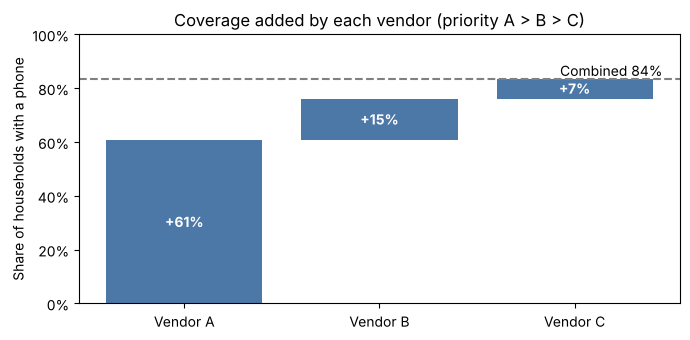

In [6]:
wf = pd.read_csv("data/output/waterfall_summary.csv")
display(wf)

v = wf[wf["order"] <= 3]
fig, ax = plt.subplots(figsize=(7, 3.5))
bottom = 0
for _, r in v.iterrows():
    add = r["new_matches_added"] / 40_000
    ax.bar(r["vendor"], add, bottom=bottom, color="#4C78A8")
    ax.text(r["vendor"], bottom + add / 2, f"+{add:.0%}", ha="center", va="center", color="white", fontweight="bold")
    bottom += add
ax.axhline(bottom, ls="--", color="gray")
ax.text(2.45, bottom + 0.01, f"Combined {bottom:.0%}", ha="right")
ax.set_ylim(0, 1); ax.set_ylabel("Share of households with a phone")
ax.yaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_title("Coverage added by each vendor (priority A > B > C)")
plt.tight_layout(); plt.show()

## 6. Match rate by segment
Match rates are lowest for rural and 18-34 households. That coverage gap is worth flagging before the
data is used for targeting or measurement.

urban_rural,rural,urban
age_band,,
18-34,52.0%,76.1%
35-49,74.7%,88.7%
50-64,81.0%,93.1%
65+,85.3%,94.7%


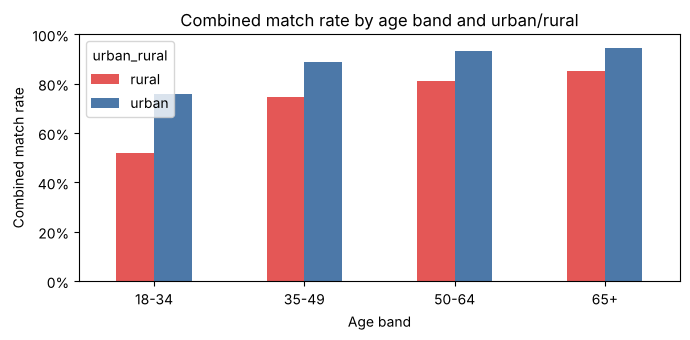

In [7]:
seg = pd.read_csv("data/output/match_by_segment.csv")
comb = seg[seg["vendor"] == "Combined (waterfall)"]
pivot = comb.pivot(index="age_band", columns="urban_rural", values="match_rate")
display(pivot.style.format("{:.1%}"))

ax = pivot.plot.bar(figsize=(7, 3.5), color=["#E45756", "#4C78A8"], rot=0)
ax.set_ylabel("Combined match rate"); ax.set_xlabel("Age band")
ax.yaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_ylim(0, 1); ax.set_title("Combined match rate by age band and urban/rural")
plt.tight_layout(); plt.show()

## 7. Vendor agreement
Where two vendors both return a phone, how often is it the same number? Low agreement suggests at least
one vendor's data is stale.

In [8]:
pd.read_csv("data/output/vendor_agreement.csv")

,pair,overlap_households,same_phone,agreement_rate
0,Vendor A vs Vendor B,10826,8566,0.791
1,Vendor A vs Vendor C,9123,6743,0.739
2,Vendor B vs Vendor C,6477,4370,0.675


## 8. Downstream outcomes: call results by source vendor
Match rate is only half the story. This simulated feedback loop shows what happened when the phones were
called. Vendor C has the highest share of disconnected and wrong numbers.

call_result,Completed interview,Disconnected,No answer / refused,Wrong number
source_vendor,,,,
Vendor A,50.4%,13.7%,33.2%,2.7%
Vendor B,47.1%,17.2%,30.3%,5.3%
Vendor C,43.9%,20.3%,28.5%,7.2%


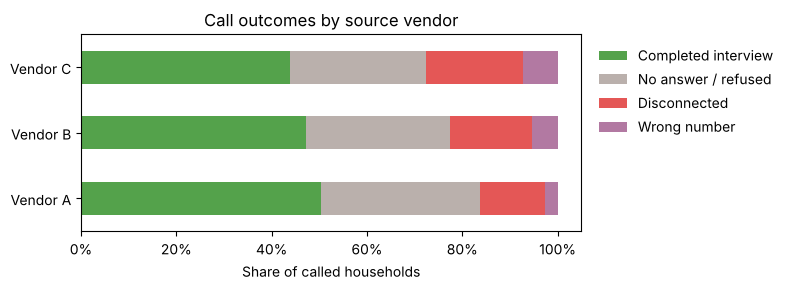

In [9]:
out = pd.read_csv("data/output/call_outcomes.csv")
tab = out.pivot(index="source_vendor", columns="call_result", values="share")
display(tab.style.format("{:.1%}"))

order = ["Completed interview", "No answer / refused", "Disconnected", "Wrong number"]
ax = tab[order].plot.barh(stacked=True, figsize=(8, 3), color=["#54A24B", "#BAB0AC", "#E45756", "#B279A2"])
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_xlabel("Share of called households"); ax.set_ylabel("")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False)
ax.set_title("Call outcomes by source vendor")
plt.tight_layout(); plt.show()

## 9. Takeaways
- **Validate before loading.** Every planted problem (duplicates, invalid phones, missing records, unknown IDs, a layout change) is caught automatically.
- **A layout map makes vendor changes cheap.** When a vendor renames a field, only one config entry changes.
- **Combine vendors, but measure what each adds.** B and C raise coverage from ~61% to ~84%, but C adds the least and has the most bad numbers.
- **Report coverage gaps.** Rural and younger households are under-covered and need a different contact strategy.

Interactive dashboards: [Tableau Public](https://public.tableau.com/app/profile/marcela.hladilova/viz/VendorDataAppendValidationCoverage/Dashboard_VendorPerfrm#1)